In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, MultiHeadAttention, LayerNormalization, Dense, Dropout, GlobalAveragePooling1D, Lambda
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import json
import matplotlib.pyplot as plt

In [2]:
class GroceryRecommender:
    def __init__(self):
        self.model = None
        self.tokenizer = None
        self.max_len = None
    
    class AttentionMaskLayer(tf.keras.layers.Layer):
        def call(self, inputs):
            # Create mask from non-zero inputs
            mask = tf.cast(tf.math.not_equal(inputs, 0), tf.float32)
            # Add dimensions for attention heads
            return mask[:, tf.newaxis, tf.newaxis, :]
    
    def build_model(self, num_items, max_len, embedding_dim=128, num_heads=4, ff_dim=256):
        inputs = Input(shape=(max_len,))
        
        # Embedding layer
        embedding = Embedding(
            input_dim=num_items,
            output_dim=embedding_dim,
            mask_zero=False  # We handle masking manually
        )(inputs)
        
        # Create attention mask using custom layer
        mask = self.AttentionMaskLayer()(inputs)
        
        # Multi-head attention with proper key_dim calculation
        key_dim = max(embedding_dim // num_heads, 1)  # Ensure at least 1
        attn_output = MultiHeadAttention(
            num_heads=num_heads,
            key_dim=key_dim
        )(embedding, embedding, attention_mask=mask)
        
        attn_output = Dropout(0.2)(attn_output)
        out1 = LayerNormalization(epsilon=1e-6)(embedding + attn_output)
        
        # Feed forward network
        ffn_output = Dense(ff_dim, activation="gelu")(out1)
        ffn_output = Dense(embedding_dim)(ffn_output)
        out2 = LayerNormalization(epsilon=1e-6)(out1 + ffn_output)
        
        # Output
        pooled_output = GlobalAveragePooling1D()(out2)
        outputs = Dense(num_items, activation="softmax")(pooled_output)
        
        model = Model(inputs=inputs, outputs=outputs)


        # Visualize the model architecture
        tf.keras.utils.plot_model(
            model,
            to_file='model_architecture.png',
            show_shapes=True,
            show_layer_names=True,
            rankdir='TB',  # TB = top to bottom, LR = left to right
            dpi=96,
            expand_nested=True
        )
        print("Model architecture saved as 'model_architecture.png'")

        model.compile(
            optimizer=Adam(learning_rate=0.001),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )
        return model
    
    def prepare_data(self, sequences):
        # Create tokenizer
        self.tokenizer = Tokenizer(oov_token="<OOV>")
        self.tokenizer.fit_on_texts([' '.join(seq) for seq in sequences])
        
        # Convert to sequences
        seq_int = self.tokenizer.texts_to_sequences([' '.join(s) for s in sequences])
        
        # Create input-output pairs
        X, y = [], []
        for seq in seq_int:
            for i in range(1, len(seq)):
                X.append(seq[:i])
                y.append(seq[i])
        
        # Pad sequences
        lengths = [len(x) for x in X]
        self.max_len = int(np.percentile(lengths, 95))
        X = pad_sequences(X, maxlen=self.max_len, padding='pre')
        
        # Convert y to categorical
        num_items = len(self.tokenizer.word_index) + 1
        y = tf.keras.utils.to_categorical(y, num_classes=num_items)
        
        return X, y, num_items
    
    def train(self, data_path, epochs=20, batch_size=64):
        # Load data
        df = pd.read_csv(data_path)
        df['items'] = df['items'].apply(eval)
        
        # Filter and prepare sequences
        sequences = [basket for basket in df['items'] if len(basket) >= 3]
        X, y, num_items = self.prepare_data(sequences)
        
        # Split data
        X_train, X_val, y_train, y_val = train_test_split(
            X, y, test_size=0.2, random_state=42
        )
        
        # Build and train model
        self.model = self.build_model(num_items, self.max_len)
        
        history = self.model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            callbacks=[
                tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
                tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2)
            ]
        )
        self.model.summary()  # Add this line

        return history
    
    def save_model(self, model_path="grocery_model.h5", tokenizer_path="tokenizer.json"):
        self.model.save(model_path)
        with open(tokenizer_path, 'w') as f:
            json.dump(self.tokenizer.to_json(), f)
    
    def load_model(self, model_path="grocery_model.h5", tokenizer_path="tokenizer.json"):
        self.model = tf.keras.models.load_model(
            model_path,
            custom_objects={'AttentionMaskLayer': self.AttentionMaskLayer}
        )
        with open(tokenizer_path) as f:
            tokenizer_json = json.load(f)
            self.tokenizer = tf.keras.preprocessing.text.tokenizer_from_json(tokenizer_json)
        
        # Infer max_len from model input shape
        self.max_len = self.model.input_shape[1]
    
    def recommend(self, current_items, top_k=5, temperature=1.0):
        if not current_items or not self.model or not self.tokenizer:
            return []
        
        try:
            # Convert to sequence
            seq = self.tokenizer.texts_to_sequences([' '.join(current_items)])[0]
            padded_seq = pad_sequences([seq], maxlen=self.max_len, padding='pre')
            
            # Predict with temperature
            logits = self.model.predict(padded_seq, verbose=0)[0]
            logits = logits / temperature
            exp_logits = np.exp(logits - np.max(logits))
            probs = exp_logits / np.sum(exp_logits)
            
            # Get top predictions
            top_indices = np.argsort(probs)[-top_k:][::-1]
            recommendations = []
            for i in top_indices:
                if i in self.tokenizer.index_word and i != 0:
                    recommendations.append({
                        "item": self.tokenizer.index_word[i],
                        "probability": float(probs[i]),
                        "score": float(logits[i])
                    })
            return recommendations
        except Exception as e:
            print(f"Recommendation error: {e}")
            return []

In [3]:
if __name__ == "__main__":

    recommender = GroceryRecommender()
    
    # Train new model
    print("Training model...")
    history = recommender.train("/kaggle/input/grocery-item-pattern-dataset/grocery_cooccurrence_dataset_v2.csv")
    
    # Save model
    recommender.save_model()
    
    # Test recommendations
    test_cases = [
        ["milk whole", "cereal"],
        ["bread white"],
        ["pasta", "tomato sauce"],
        ["yogurt greek"],
        []  # Empty basket
    ]
    
    for items in test_cases:
        print(f"\nCurrent items: {items}")
        recs = recommender.recommend(items, temperature=0.5)
        for rec in recs:
            print(f"- {rec['item']} (prob: {rec['probability']:.3f})")

Training model...
Model architecture saved as 'model_architecture.png'
Epoch 1/20
13904/13904 ━━━━━━━━━━━━━━━━━━━━ 87s 6ms/step - accuracy: 0.4375 - loss: 2.0383 - val_accuracy: 0.7006 - val_loss: 0.9442 - learning_rate: 0.0010
Epoch 2/20
13904/13904 ━━━━━━━━━━━━━━━━━━━━ 74s 5ms/step - accuracy: 0.7267 - loss: 0.8588 - val_accuracy: 0.7532 - val_loss: 0.7735 - learning_rate: 0.0010
Epoch 3/20
13904/13904 ━━━━━━━━━━━━━━━━━━━━ 74s 5ms/step - accuracy: 0.7607 - loss: 0.7309 - val_accuracy: 0.7732 - val_loss: 0.7021 - learning_rate: 0.0010
Epoch 4/20
13904/13904 ━━━━━━━━━━━━━━━━━━━━ 75s 5ms/step - accuracy: 0.7746 - loss: 0.6778 - val_accuracy: 0.7768 - val_loss: 0.6751 - learning_rate: 0.0010
Epoch 5/20
13904/13904 ━━━━━━━━━━━━━━━━━━━━ 75s 5ms/step - accuracy: 0.7836 - loss: 0.6440 - val_accuracy: 0.7858 - val_loss: 0.6403 - learning_rate: 0.0010
Epoch 6/20
13904/13904 ━━━━━━━━━━━━━━━━━━━━ 75s 5ms/step - accuracy: 0.7887 - loss: 0.6247 - val_accuracy: 0.7862 - val_loss: 0.6341 - learning_

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 113)            │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ embedding (Embedding)     │ (None, 113, 128)       │         48,896 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ attention_mask_layer      │ (None, 1, 1, 113)      │              0 │ input_layer[0][0]      │
│ (AttentionMaskLayer)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ multi_head_attention      │ (None, 113, 128)       │         66,048 │ embedding[0][0],       │
│ (MultiHeadAttention)      │                        │                │ embedding[0][0],       │
│                           │                        │                │ attention_mask_layer[… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 113, 128)       │              0 │ multi_head_attention[… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add (Add)                 │ (None, 113, 128)       │              0 │ embedding[0][0],       │
│                           │                        │                │ dropout_1[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ layer_normalization       │ (None, 113, 128)       │            256 │ add[0][0]              │
│ (LayerNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 113, 256)       │         33,024 │ layer_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_1 (Dense)           │ (None, 113, 128)       │         32,896 │ dense[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add_1 (Add)               │ (None, 113, 128)       │              0 │ layer_normalization[0… │
│                           │                        │                │ dense_1[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ layer_normalization_1     │ (None, 113, 128)       │            256 │ add_1[0][0]            │
│ (LayerNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ global_average_pooling1d  │ (None, 128)            │              0 │ layer_normalization_1… │
│ (GlobalAveragePooling1D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_2 (Dense)           │ (None, 382)            │         49,278 │ global_average_poolin… │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 691,964 (2.64 MB)

 Trainable params: 230,654 (900.99 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 461,310 (1.76 MB)


Current items: ['milk whole', 'cereal']
- dumbbells (prob: 0.019)
- basketball (prob: 0.003)
- equipment (prob: 0.003)
- fish (prob: 0.003)
- case (prob: 0.003)

Current items: ['bread white']
- vinaigrette (prob: 0.006)
- sleeping (prob: 0.005)
- food (prob: 0.004)
- tent (prob: 0.003)
- beef (prob: 0.003)

Current items: ['pasta', 'tomato sauce']
- cheese (prob: 0.009)
- soda (prob: 0.004)
- charger (prob: 0.003)
- diapers (prob: 0.003)
- chips (prob: 0.003)

Current items: ['yogurt greek']
- wet (prob: 0.005)
- snacks (prob: 0.003)
- cream (prob: 0.003)
- popcorn (prob: 0.003)
- canned (prob: 0.003)

Current items: []


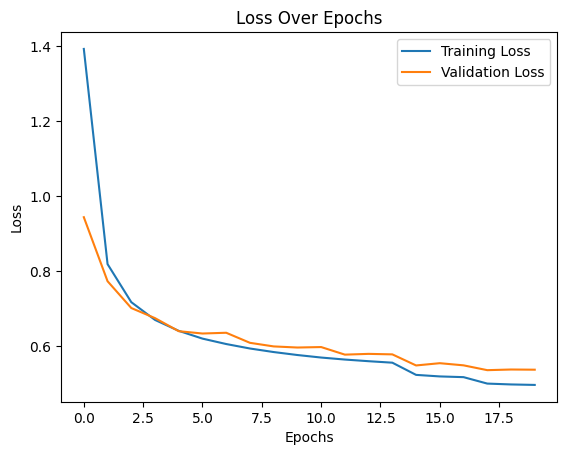

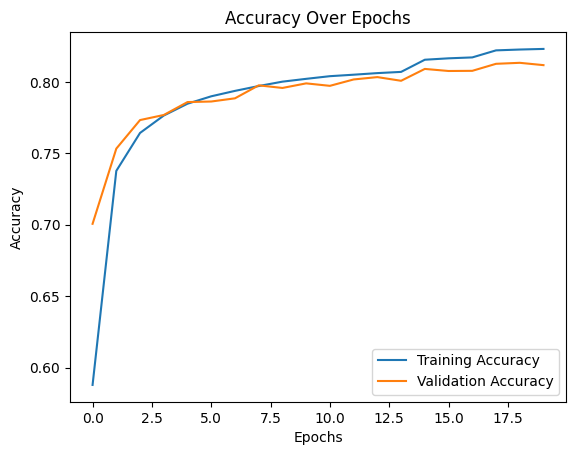

In [4]:
# Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()